# Validasi Data, Prediksi Efisiensi & Deteksi Anomali Sensor Pembangkit Listrik

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aldo02032004/power-plant-anomaly/blob/main/power_plant_anomaly.ipynb)

Notebook ini menjawab empat pertanyaan tentang data sensor pembangkit listrik tenaga uap selama 2022:
1. Apakah angka di data konsisten dengan rumus fisikanya?
2. Bisakah efisiensi boiler dan turbin diprediksi, dan berapa menit ke depan?
3. Sensor mana yang paling berpengaruh pada prediksi efisiensi?
4. Kapan sensor menunjukkan nilai tidak wajar, dan seberapa andal detektornya?

## 1. Data

Data CSV diunduh dari Google Drive: 50.091 baris, satu baris per 10 menit, Januari–Desember 2022. Kolom dibagi tiga:
- **target**: efisiensi HP turbine dan efisiensi boiler;
- **turunan**: angka yang *dihitung* dari sensor lewat rumus (entalpi, heat rate, dsb.);
- **sensor**: 40 besaran yang diukur langsung (suhu, tekanan, aliran, emisi, beban).

In [1]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

CSV = 'industrial_dataset.csv'
if not os.path.exists(CSV):
    import gdown
    gdown.download(id='1B89CtLiDWSVutzxSLESP7O9XWwqh9mQX', output=CSV, quiet=True)
df = pd.read_csv(CSV, parse_dates=['Timestamp']).sort_values('Timestamp').reset_index(drop=True)

TARGET = ['HP Turbine eff (%)', 'Boiler Eff (%)']
TURUNAN = ['Entalphy inlet MS (kj/kg)', 'Entropi Inlet MS (Kj/Kg (Deg C))', 'Entalphy Cold Reheat (kj/kg)',
           'Entalphy Isentropis Cold Reheat (kj/kg)', 'ΔP aktual (Kj/Kg)', 'ΔHP isentropis (Kj/Kg)',
           'APH Leakage (%)', 'Corrected Flue Gas Out Temperature (°C)', 'APH Effectiveness (%)',
           'Energy Input From Boiler (Kcal/h)', 'NTHR (Kcal/Kwh)', 'NPHR (Kcal/Kwh)']
SENSOR = [c for c in df.columns if c not in ['Timestamp', *TARGET, *TURUNAN]]

fmt = lambda x, d=2: f'{round(x, d) + 0:,.{d}f}'.translate(str.maketrans(',.', '.,'))  # format angka Indonesia
os.makedirs('images', exist_ok=True)

## 2. Validasi: apakah angka di data masuk akal?

Sebelum membuat model, kita pastikan datanya bisa dipercaya. Ada tiga jenis cek:
- **Rumus**: kolom turunan harus sama dengan hasil rumusnya (toleransi 0,1%). Contohnya, efisiensi HP turbine = penurunan entalpi aktual ÷ penurunan entalpi isentropis × 100.
- **Fisik**: hubungan dasar harus terpenuhi di setiap baris. Contohnya, beban netto lebih kecil dari beban bruto.
- **Keterkaitan**: besaran yang secara fisik saling bergantung harus berkorelasi. Contohnya, makin besar aliran uap, makin besar listrik yang dihasilkan.

Cek rumus dan fisik **Lulus** bila terpenuhi di ≥ 99% baris. Cek keterkaitan Lulus bila korelasi Spearman ρ ≥ 0,5.

In [2]:
h_ms, dp, dhs = df['Entalphy inlet MS (kj/kg)'], df['ΔP aktual (Kj/Kg)'], df['ΔHP isentropis (Kj/Kg)']
rumus = {  # cek: (nilai di data, nilai dari rumus)
    'ΔP aktual = h_MS − h_CRH': (dp, h_ms - df['Entalphy Cold Reheat (kj/kg)']),
    'ΔH isentropis = h_MS − h_CRH,s': (dhs, h_ms - df['Entalphy Isentropis Cold Reheat (kj/kg)']),
    'η HP = ΔP ÷ ΔH isentropis × 100': (df['HP Turbine eff (%)'], dp / dhs * 100),
    'NTHR = energi input ÷ Nett Load': (df['NTHR (Kcal/Kwh)'], df['Energy Input From Boiler (Kcal/h)'] / (df['Nett Load (MW)'] * 1e3)),
    'NPHR = NTHR ÷ η boiler': (df['NPHR (Kcal/Kwh)'], df['NTHR (Kcal/Kwh)'] / (df['Boiler Eff (%)'] / 100)),
}
fisik = {
    'Nett Load < Gross Load': df['Nett Load (MW)'] < df['Gross Load (MW)'],
    'Suhu uap utama: turbin ≤ boiler': df['Main steam temperature (turbine side) (℃)'] <= df['Main steam temperature (boiler side) (℃)'],
    'Interval 10 menit, tanpa missing': df['Timestamp'].diff().fillna(pd.Timedelta('10min')).eq(pd.Timedelta('10min')) & df.notna().all(axis=1),
}
keterkaitan = {
    'Main steam flow ↔ Gross Load': ('Main steam flow (t/h)', 'Gross Load (MW)'),
    'Coal Flow ↔ Gross Load': ('Coal Flow (t/h)', 'Gross Load (MW)'),
    'Gross Load ↔ Nett Load': ('Gross Load (MW)', 'Nett Load (MW)'),
}
rho = df.drop(columns='Timestamp').corr(method='spearman').abs()
rho_maks = rho.mask(np.eye(len(rho), dtype=bool)).max().max()

validasi = pd.DataFrame(
    [('Rumus', k, np.isclose(a, b, rtol=1e-3).mean(), 0.99) for k, (a, b) in rumus.items()]
    + [('Fisik', k, m.mean(), 0.99) for k, m in fisik.items()]
    + [('Keterkaitan', k, df[a].corr(df[b], method='spearman'), 0.5) for k, (a, b) in keterkaitan.items()]
    + [('Keterkaitan', '|ρ| tertinggi dari semua pasangan kolom', rho_maks, 0.5)],
    columns=['Jenis', 'Cek', 'Nilai', 'Batas'])
validasi['Status'] = np.where(validasi['Nilai'] >= validasi['Batas'], 'Lulus', 'Gagal')
validasi.style.format({'Nilai': lambda v: fmt(v, 3), 'Batas': lambda v: fmt(v, 2)}).hide(axis='index')

Jenis,Cek,Nilai,Batas,Status
Rumus,ΔP aktual = h_MS − h_CRH,"0,101","0,99",Gagal
Rumus,"ΔH isentropis = h_MS − h_CRH,s","0,124","0,99",Gagal
Rumus,η HP = ΔP ÷ ΔH isentropis × 100,"0,116","0,99",Gagal
Rumus,NTHR = energi input ÷ Nett Load,"0,065","0,99",Gagal
Rumus,NPHR = NTHR ÷ η boiler,"0,066","0,99",Gagal
Fisik,Nett Load < Gross Load,"1,000","0,99",Lulus
Fisik,Suhu uap utama: turbin ≤ boiler,"0,997","0,99",Lulus
Fisik,"Interval 10 menit, tanpa missing","1,000","0,99",Lulus
Keterkaitan,Main steam flow ↔ Gross Load,"-0,002","0,50",Gagal
Keterkaitan,Coal Flow ↔ Gross Load,"0,002","0,50",Gagal


**Temuan.** Semua cek fisik lulus: Nett < Gross di 100% baris, interval rapi, tanpa missing. Tetapi semua cek rumus gagal. η HP hanya cocok dengan ΔP ÷ ΔH isentropis di 11,6% baris, dan NTHR hanya di 6,5%.

Sensor yang seharusnya bergerak bersama juga tidak berkorelasi, misalnya Main steam flow ↔ Gross Load (ρ = −0,002). Korelasi tertinggi dari 1.431 pasangan kolom hanya 0,023. Artinya setiap kolom berubah sendiri-sendiri, ciri data sintetis yang dibangkitkan per kolom, bukan rekaman pembangkit nyata.

## 3. Cek sinyal: bisakah efisiensi diprediksi dari sensor?

Model *gradient boosting* dilatih untuk menebak efisiensi dari 40 sensor. Hasilnya dibandingkan dengan *baseline* yang selalu menebak rata-rata.
- **Skema uji:** `TimeSeriesSplit` (5 fold). Model selalu dilatih di periode lebih awal dan diuji di periode sesudahnya, sehingga tidak ada informasi dari masa depan.
- **Cara membaca R²:** R² = 1 berarti tebakan sempurna. R² ≤ 0 berarti model tidak lebih baik dari menebak rata-rata.
- **Baris terakhir sengaja memakai kolom turunan.** Kolom ini dihitung dari target itu sendiri (*data leakage*). Pada data yang sehat, R²-nya akan mendekati 1.

In [3]:
cv = TimeSeriesSplit(n_splits=5)
r2 = lambda model, X, y: cross_val_score(model, X, y, cv=cv, scoring='r2').mean()
hgb = HistGradientBoostingRegressor(random_state=0)
sinyal = pd.DataFrame({y: {
    'Baseline (rata-rata)': r2(DummyRegressor(), df[SENSOR], df[y]),
    'Boosting, 40 sensor': r2(hgb, df[SENSOR], df[y]),
    'Boosting, + kolom turunan (leakage)': r2(hgb, df.drop(columns=['Timestamp', y]), df[y]),
} for y in TARGET})
sinyal.style.format(lambda v: fmt(v, 3))

,HP Turbine eff (%),Boiler Eff (%)
Baseline (rata-rata),"-0,001","0,000"
"Boosting, 40 sensor","-0,025","-0,025"
"Boosting, + kolom turunan (leakage)","-0,029","-0,028"


**Temuan.** Semua R² ≤ 0, bahkan ketika kolom turunan ikut dipakai. Ini sejalan dengan hasil validasi: kolom-kolomnya memang tidak saling terhubung. Karena sensor tidak bisa menjelaskan efisiensi pada saat yang sama, section berikutnya memprediksi efisiensi dari pola waktunya sendiri.

## 4. Prediksi efisiensi (forecasting dengan LightGBM)

Karena sensor tidak bisa menjelaskan efisiensi pada saat yang sama, kita coba pertanyaan yang lebih praktis: **berapa efisiensi 10, 20, 30 dan 60 menit ke depan?**
- **Fitur:** efisiensi 6 pengukuran terakhir (riwayat 10–60 menit) ditambah 40 sensor pada pengukuran terakhir. Semua fitur sudah tersedia saat prediksi dibuat, jadi tidak ada informasi dari masa depan.
- **Model:** LightGBM, dilatih di 80% awal periode (Januari–Oktober) dan diuji di 20% akhir (Oktober–Desember).
- **Pembanding:** *persistence*, yaitu menebak bahwa efisiensi nanti sama dengan nilai terakhir. Model baru berguna kalau mengalahkan pembanding ini.
- **Varian "riwayat saja":** dipakai untuk melihat apakah 40 sensor benar-benar menambah akurasi.

In [4]:
import lightgbm as lgb
from sklearn.metrics import r2_score, mean_absolute_error

LGB = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=0, verbose=-1)
HORIZON = [1, 2, 3, 6]  # langkah 10 menit

def data_forecast(y, h):
    riwayat = pd.concat({f'Riwayat efisiensi ke-{k}': df[y].shift(h + k - 1) for k in range(1, 7)}, axis=1)
    X = pd.concat([riwayat, df[SENSOR].shift(h)], axis=1).dropna()
    n = int(len(X) * 0.8)
    return X[:n], X[n:], df[y][X.index][:n], df[y][X.index][n:], list(riwayat)

hasil, model = [], {}
for y in TARGET:
    for h in HORIZON:
        Xtr, Xte, ytr, yte, riw = data_forecast(y, h)
        m = lgb.LGBMRegressor(**LGB).fit(Xtr, ytr)
        pred = {'Persistence (nilai terakhir)': Xte[riw[0]],
                'LightGBM: riwayat saja': lgb.LGBMRegressor(**LGB).fit(Xtr[riw], ytr).predict(Xte[riw]),
                'LightGBM: riwayat + 40 sensor': m.predict(Xte)}
        hasil += [(y, 10 * h, k, r2_score(yte, p), mean_absolute_error(yte, p)) for k, p in pred.items()]
        if h == 1:
            model[y] = (m, Xte, yte, pred['LightGBM: riwayat + 40 sensor'])
hasil = pd.DataFrame(hasil, columns=['Target', 'Menit ke depan', 'Model', 'R²', 'MAE'])
hasil.pivot_table(index=['Target', 'Model'], columns='Menit ke depan', values='R²', sort=False).style.format(lambda v: fmt(v, 3))

**Temuan.** Untuk 10 menit ke depan, LightGBM mencapai R² 0,82 untuk kedua efisiensi, jauh di atas persistence (0,56). Rata-rata meleset sekitar 0,11 poin persen untuk HP turbine. Kemampuannya turun cepat: R² 0,26–0,28 di 20 menit, dan ≈ 0 mulai 30 menit.

Menambah 40 sensor tidak memperbaiki prediksi; R²-nya malah sedikit lebih rendah (0,818 vs 0,822). Jadi prediksi bertumpu pada pola waktu efisiensi itu sendiri, dan cocok sebagai peringatan dini jangka sangat pendek.

## 5. Sensor mana yang paling berpengaruh?

Pengaruh tiap fitur diukur dengan **permutation importance** pada data uji (model 10 menit ke depan):
1. Nilai satu fitur diacak sehingga hubungannya dengan efisiensi putus.
2. Kita ukur berapa R² turun. Pengacakan diulang 5 kali.

Cara membacanya:
- **ΔR² positif:** fitur itu **membantu** prediksi. Makin besar, makin penting.
- **ΔR² negatif:** prediksi justru lebih baik tanpa fitur itu, jadi fitur itu **merugikan** (menambah noise).
- **Nilai lebih kecil dari simpangan pengacakan (std):** pengaruhnya tidak bisa dibedakan dari nol.

In [5]:
from sklearn.inspection import permutation_importance

def r2_acak(m, Xte, yte, kolom):  # R² setelah sekelompok kolom diacak bersama
    Xa = Xte.copy()
    Xa[kolom] = Xa[kolom].sample(frac=1, random_state=0).to_numpy()
    return r2_score(yte, m.predict(Xa))

pengaruh, ringkas = {}, {}
for y, (m, Xte, yte, pred) in model.items():
    pi = permutation_importance(m, Xte, yte, scoring='r2', n_repeats=5, random_state=0)
    p = pengaruh[y] = pd.DataFrame({'ΔR²': pi.importances_mean, 'std': pi.importances_std}, index=Xte.columns).loc[SENSOR]
    top, bawah = p['ΔR²'].idxmax(), p['ΔR²'].idxmin()
    ringkas[y] = {'R² model (riwayat + sensor)': fmt(r2_score(yte, pred), 3),
                  'R² jika riwayat efisiensi diacak': fmt(r2_acak(m, Xte, yte, [c for c in Xte if c not in SENSOR]), 3),
                  'R² jika 40 sensor diacak': fmt(r2_acak(m, Xte, yte, SENSOR), 3),
                  'Sensor paling membantu (ΔR² × 10⁻⁴)': f"{top}: {fmt(p.loc[top, 'ΔR²'] * 1e4, 1)} ± {fmt(p.loc[top, 'std'] * 1e4, 1)}",
                  'Sensor paling merugikan (ΔR² × 10⁻⁴)': f"{bawah}: {fmt(p.loc[bawah, 'ΔR²'] * 1e4, 1)} ± {fmt(p.loc[bawah, 'std'] * 1e4, 1)}"}
pd.DataFrame(ringkas)

,HP Turbine eff (%),Boiler Eff (%)
R² model (riwayat + sensor),"0,818","0,814"
R² jika riwayat efisiensi diacak,"-0,792","-0,760"
R² jika 40 sensor diacak,"0,818","0,814"
Sensor paling membantu (ΔR² × 10⁻⁴),"SO2 (mg/m3): 0,8 ± 0,6","High exhaust pressure (Mpa): 1,0 ± 0,5"
Sensor paling merugikan (ΔR² × 10⁻⁴),"Gross Load (MW): -0,7 ± 0,4","Reheater desuperheating water flow (t/h): -0,9..."


**Temuan.** Hampir seluruh kemampuan prediksi berasal dari **riwayat efisiensi**. Kalau riwayat diacak, R² jatuh dari 0,82 ke sekitar −0,8. Kalau ke-40 sensor diacak sekaligus, R² tidak berubah (0,818).

Sensor yang paling membantu adalah SO2 untuk HP turbine dan High exhaust pressure untuk boiler. Pengaruhnya hanya ±1 × 10⁻⁴ R², sebesar noise pengacakan. Sensor yang paling merugikan adalah Gross Load untuk HP turbine dan Reheater desuperheating water flow untuk boiler, dengan pengaruh sekecil itu juga. Karena itu urutan sensor di slide 3 sebaiknya **tidak** dibaca sebagai faktor operasi yang menentukan efisiensi. Urutan itu konsisten dengan hasil validasi: di data ini sensor memang tidak terhubung dengan efisiensi.

## 6. Deteksi anomali sensor

Setiap sensor diubah menjadi **robust z-score**: (nilai − median) ÷ (1,4826 × MAD), dengan MAD = median simpangan absolut. Median dan MAD tidak terseret oleh nilai ekstrem, jadi anomali tidak "menyamarkan" dirinya sendiri.

Satu baris ditandai anomali bila ada sensor dengan |z| > 4,5, dan sensor itulah penyebabnya. Baris anomali yang berurutan digabung menjadi satu **event**.

Pendekatan per sensor dipilih karena dua alasan: gangguan nyata seperti sensor rusak atau lonjakan biasanya muncul di satu atau dua sensor, dan metode ini tidak membutuhkan label.

In [6]:
BATAS_Z = 4.5
def robust_z(X):
    med = np.median(X, axis=0)
    return (X - med) / (1.4826 * np.median(np.abs(X - med), axis=0))

X = df[SENSOR].to_numpy()
Z = robust_z(X)
j = np.abs(Z).argmax(axis=1)
z_maks = Z[np.arange(len(Z)), j]
anomali = np.abs(z_maks) > BATAS_Z

a = pd.DataFrame({'Timestamp': df['Timestamp'], 'Sensor': np.array(SENSOR)[j], 'z': z_maks})[anomali]
a['Event'] = a['Timestamp'].diff().ne(pd.Timedelta('10min')).cumsum()  # baris berurutan = satu event
event = a.groupby('Event').agg(Mulai=('Timestamp', 'first'), Durasi_menit=('z', lambda z: 10 * len(z)),
                               Sensor=('Sensor', lambda s: s.mode()[0]), z_ekstrem=('z', lambda z: z[z.abs().idxmax()]))
event.style.format({'Mulai': '{:%d-%m-%Y %H:%M}', 'z_ekstrem': lambda v: fmt(v, 2)}).hide(axis='index')

Mulai,Durasi_menit,Sensor,z_ekstrem
01-01-2022 10:20,40,SO2 (mg/m3),"-4,73"
01-01-2022 13:00,10,Opacity (%),"-4,78"
04-01-2022 18:20,10,Superheater desuperheating water flow (t/h),"4,51"
08-01-2022 18:10,10,Dust (mg/m3),"-4,61"
25-01-2022 00:00,10,Coal Flow (t/h),"-4,57"
08-02-2022 07:30,10,Feedwater flow (t/h),"-4,58"
22-02-2022 15:50,10,HHV (Kcal/Kg),"-4,73"
28-04-2022 00:20,10,Pressure (Kpa),"4,87"
04-09-2022 16:50,10,O2 in APH (%),"-4,66"
28-09-2022 08:10,10,Cold Reheat Pressure (Mpa),"4,51"


**Temuan.** Sebanyak 17 baris (0,03% data) ditandai, terbagi menjadi 13 event. Event terpanjang adalah SO2 yang turun tajam selama 40 menit pada 1 Januari 2022 pukul 10:20, sedangkan event lainnya berlangsung 10–20 menit di sensor yang berbeda-beda.

Jumlah ini setara dengan yang diharapkan dari kebetulan: P(|z| > 4,5) ≈ 6,8 × 10⁻⁶ × 40 sensor × 50.091 baris ≈ 14 baris. Jadi pada data ini event lebih tepat dibaca sebagai nilai ekstrem acak, bukan gangguan operasi.

## 7. Kalibrasi detektor

Data ini tidak punya label anomali. Karena itu detektor diuji dengan **anomali buatan yang posisinya kita ketahui**: 1% baris acak diberi lonjakan sebesar k × simpangan baku pada 1–3 sensor.
- **Recall**: persentase lonjakan buatan yang tertangkap.
- **Precision**: persentase tanda anomali yang memang lonjakan buatan.

Detektor layak dipakai bila precision tinggi di semua ukuran lonjakan dan recall naik seiring besarnya lonjakan.

In [7]:
rng = np.random.default_rng(42)
def uji(k):
    Xs, benar = X.copy(), np.zeros(len(X), bool)
    for i in rng.choice(len(X), len(X) // 100, replace=False):
        kol = rng.choice(X.shape[1], rng.integers(1, 4), replace=False)
        Xs[i, kol] += rng.choice([-1, 1], len(kol)) * k * X[:, kol].std(axis=0)
        benar[i] = True
    tanda = (np.abs(robust_z(Xs)) > BATAS_Z).any(axis=1)
    return (tanda & benar).sum() / benar.sum(), (tanda & benar).sum() / tanda.sum()

K = [3, 4, 5, 6]
kalibrasi = pd.DataFrame([uji(k) for k in K], index=pd.Index(K, name='Lonjakan (× σ)'), columns=['Recall', 'Precision'])
kalibrasi.style.format(lambda v: fmt(v, 3))

,Recall,Precision
Lonjakan (× σ),,
3,"0,110","0,764"
4,"0,506","0,941"
5,"0,852","0,962"
6,"0,980","0,968"


**Temuan.** Untuk lonjakan ≥ 4σ, precision ≥ 0,94, artinya hampir setiap tanda adalah gangguan sungguhan. Recall naik dari 0,11 (3σ) ke 0,98 (6σ). Lonjakan ≥ 5σ hampir selalu tertangkap, sedangkan lonjakan 3σ sulit dibedakan dari variasi normal.

Ini batas yang wajar untuk detektor tanpa label. Ambang 4,5 bisa diturunkan bila menangkap gangguan kecil lebih penting daripada menghindari alarm palsu.

## 8. Ringkasan visual

Empat slide 16:9 disimpan di `images/`:
- **Slide 1:** hasil 12 cek validasi (hijau = lulus, merah = gagal), plus contoh efisiensi di data yang tidak mengikuti rumusnya.
- **Slide 2:** prediksi efisiensi 10 menit ke depan vs nilai aktual, dan akurasi per horizon.
- **Slide 3:** sensor yang paling membantu dan paling merugikan prediksi.
- **Slide 4:** skor anomali harian sepanjang 2022 dan hasil uji detektor dengan lonjakan buatan.

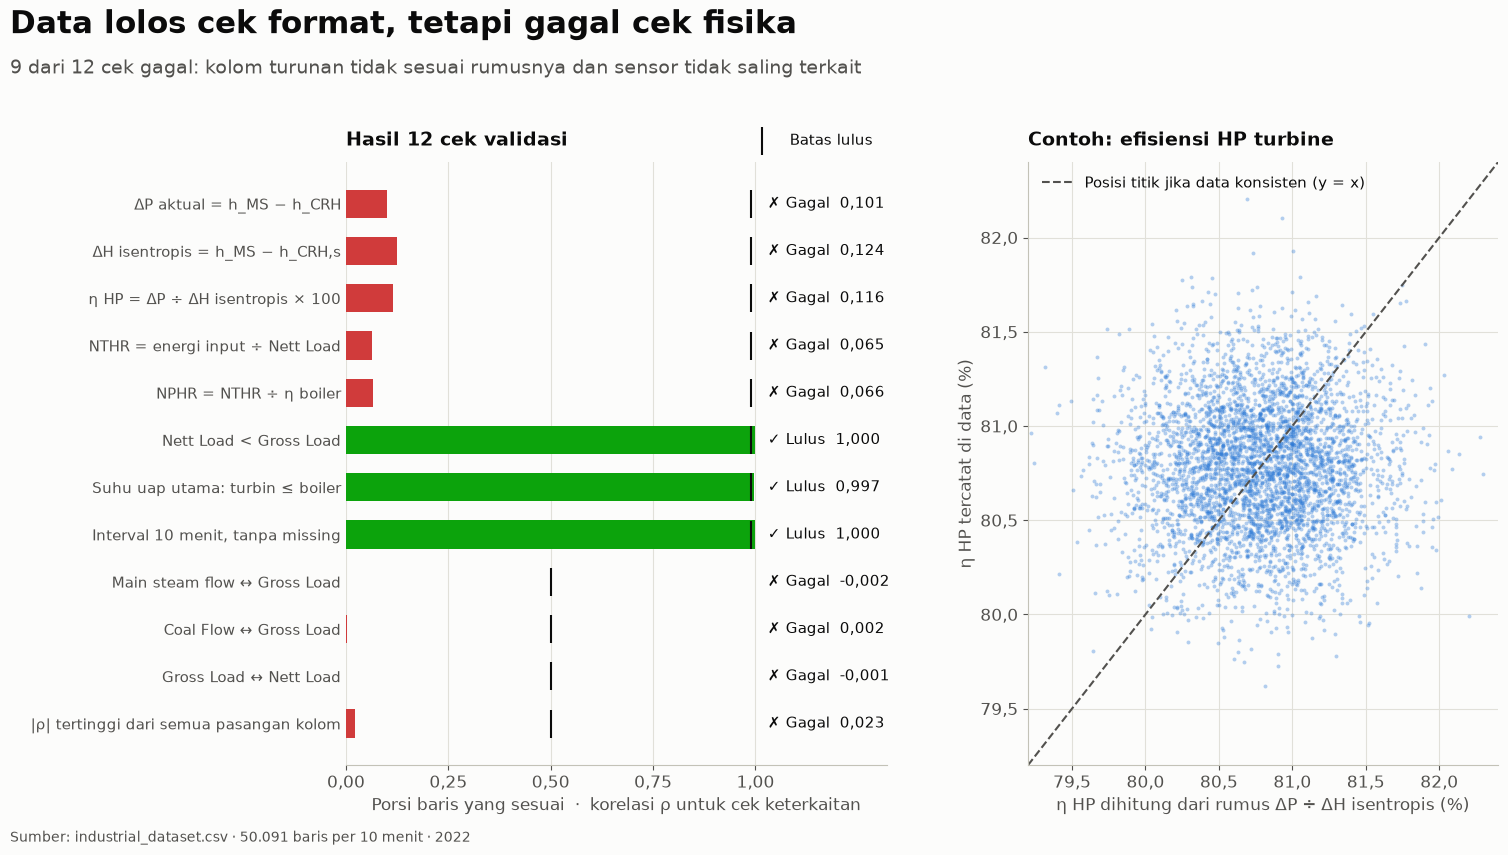

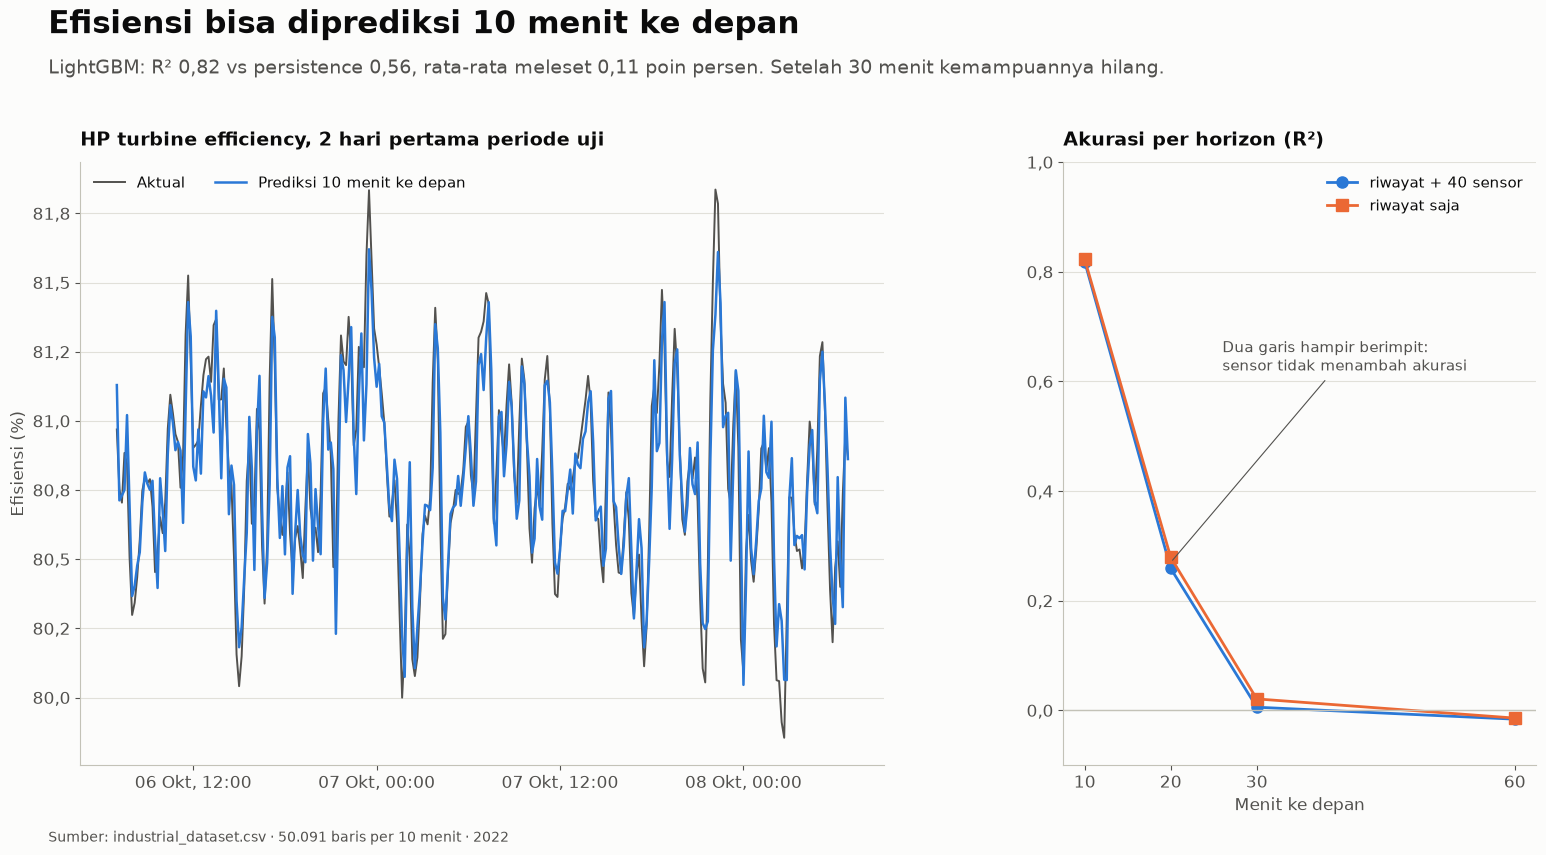

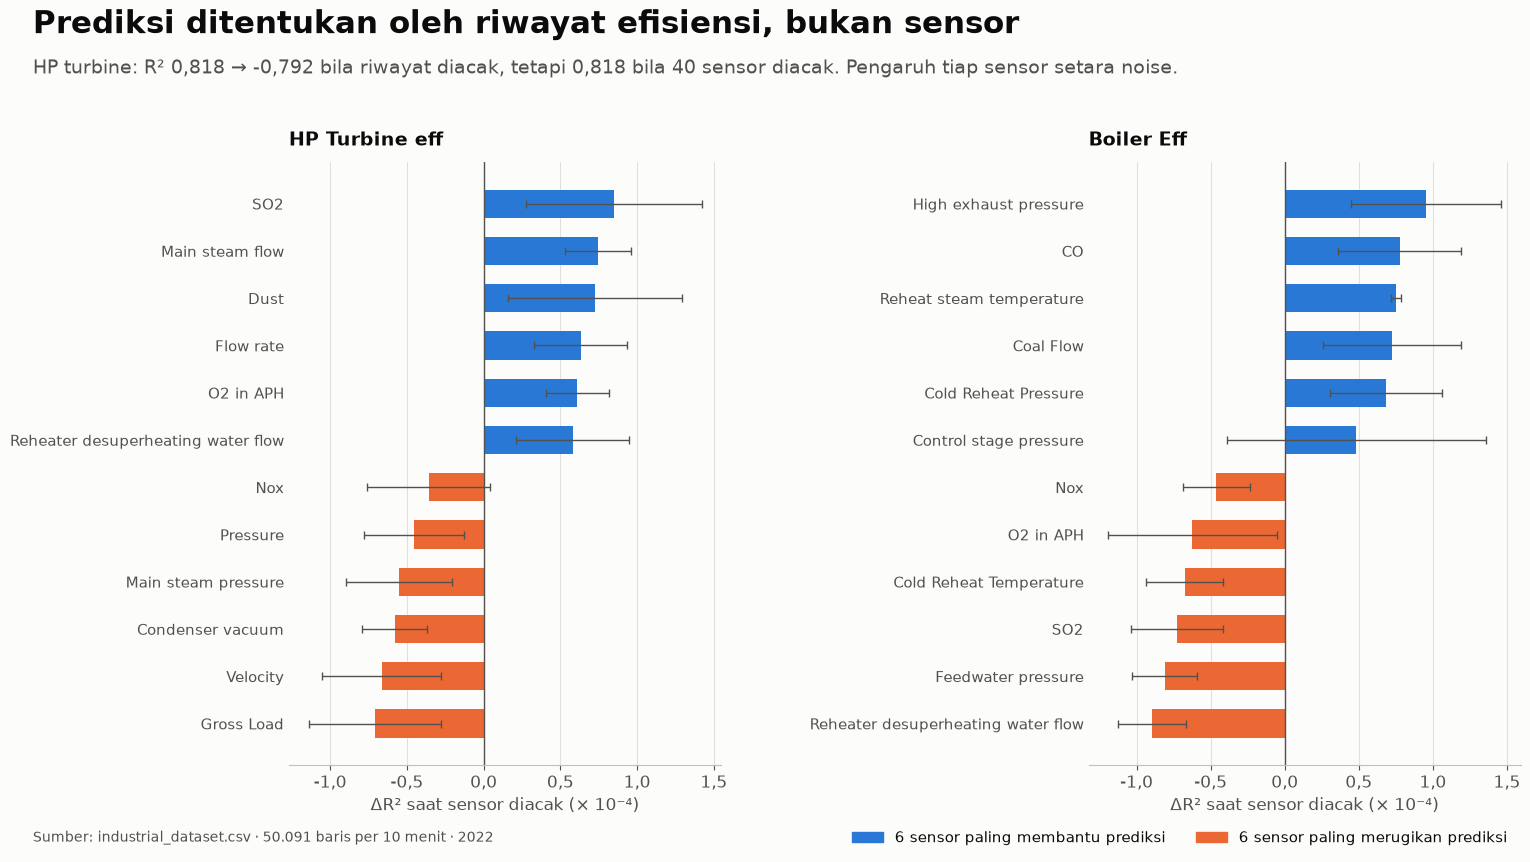

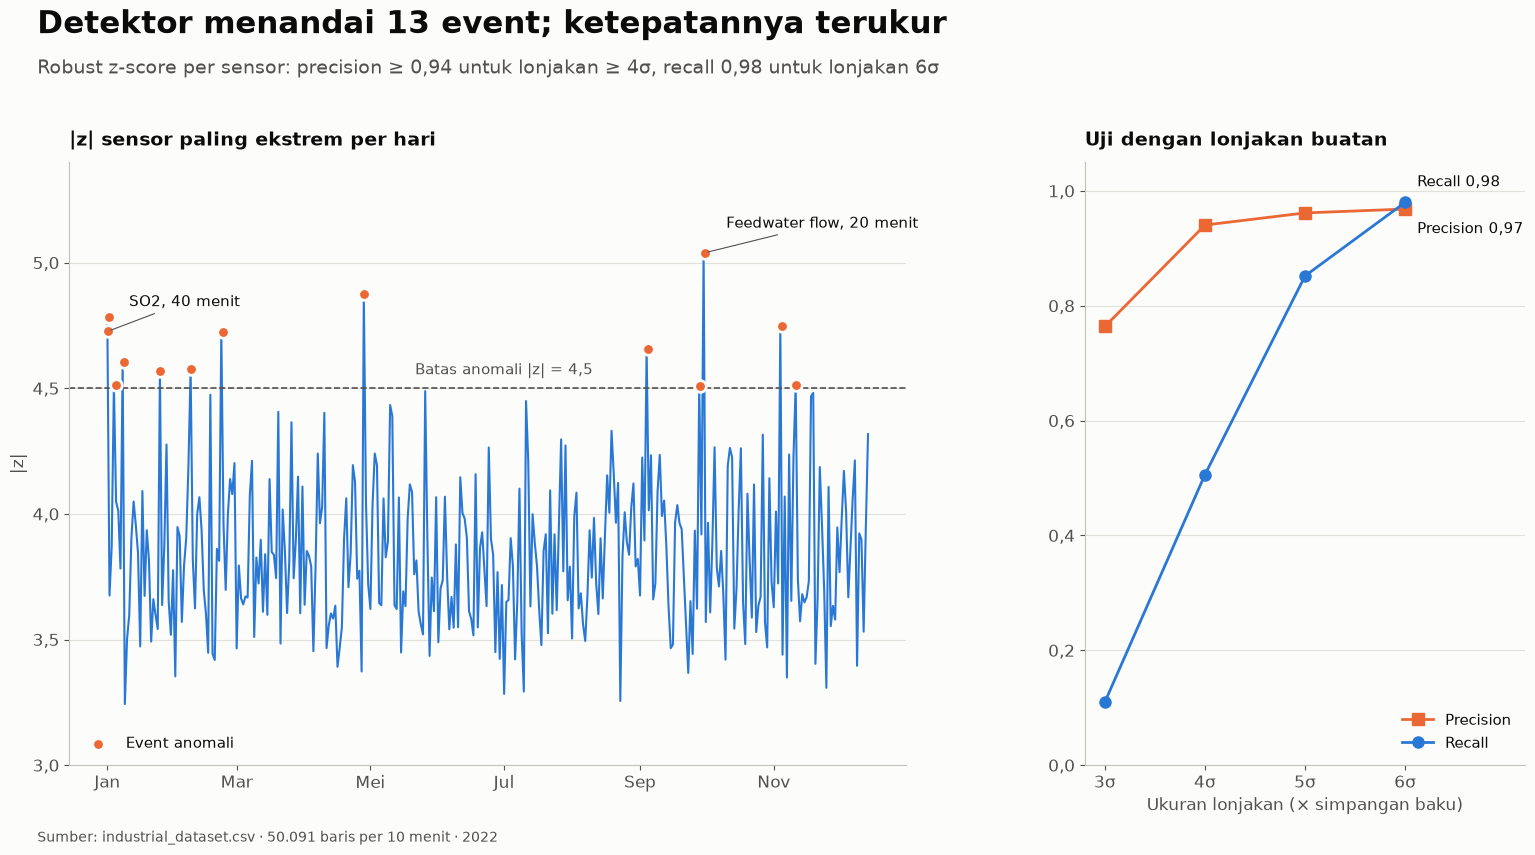

In [8]:
INK, INK2, GRID, AXIS, SURF = '#0b0b0b', '#52514e', '#e1e0d9', '#c3c2b7', '#fcfcfb'
BIRU, ORANYE, LULUS, GAGAL = '#2a78d6', '#eb6834', '#0ca30c', '#d03b3b'
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'font.size': 12, 'text.color': INK,
                     'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'axes.edgecolor': AXIS,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlesize': 14,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 12})
angka = lambda d: FuncFormatter(lambda v, _: fmt(v, d))
BLN = 'Jan Feb Mar Apr Mei Jun Jul Agu Sep Okt Nov Des'.split()
BULAN = FuncFormatter(lambda v, _: BLN[mdates.num2date(v).month - 1])

def slide(judul, sub, left=.06, **kw):
    fig, axes = plt.subplots(1, 2, figsize=(16, 9), **kw)
    fig.text(.04, .95, judul, fontsize=22, fontweight='bold', va='top')
    fig.text(.04, .895, sub, fontsize=14, color=INK2, va='top')
    fig.text(.04, .025, 'Sumber: industrial_dataset.csv · 50.091 baris per 10 menit · 2022', fontsize=10, color=INK2)
    fig.subplots_adjust(left=left, right=.97, top=.78, bottom=.11, wspace=.28)
    return fig, axes

# Slide 1: scorecard validasi + bukti rumus
fig, (ax1, ax2) = slide('Data lolos cek format, tetapi gagal cek fisika',
    f'{(validasi.Status == "Gagal").sum()} dari {len(validasi)} cek gagal: kolom turunan tidak sesuai rumusnya dan sensor tidak saling terkait',
    left=.25, gridspec_kw={'width_ratios': [1.15, 1]})
v = validasi[::-1].reset_index(drop=True)
warna = np.where(v.Status == 'Lulus', LULUS, GAGAL)
ax1.barh(v.index, v.Nilai.clip(0, 1), height=.6, color=warna)
ax1.scatter(v.Batas, v.index, marker='|', s=400, color=INK, zorder=3, label='Batas lulus')
for i, r in v.iterrows():
    ax1.text(1.03, i, f"{'✓' if r.Status == 'Lulus' else '✗'} {r.Status}  {fmt(r.Nilai, 3)}", va='center', fontsize=11)
ax1.set_yticks(v.index, v.Cek, fontsize=11)
ax1.tick_params(axis='y', length=0)
ax1.set(xlim=(0, 1.32), xticks=[0, .25, .5, .75, 1], title='Hasil 12 cek validasi')
ax1.set_xlabel('Porsi baris yang sesuai  ·  korelasi ρ untuk cek keterkaitan')
ax1.xaxis.set_major_formatter(angka(2)); ax1.grid(axis='x', color=GRID, lw=.8); ax1.set_axisbelow(True)
ax1.spines['left'].set_visible(False)
ax1.legend(loc='lower right', bbox_to_anchor=(1, 1), frameon=False, fontsize=11)

eta, eta_rumus = rumus['η HP = ΔP ÷ ΔH isentropis × 100']
s = df.sample(4000, random_state=0).index
ax2.scatter(eta_rumus[s], eta[s], s=8, alpha=.35, color=BIRU, linewidths=0)
lim = [79.2, 82.4]
ax2.plot(lim, lim, color=INK2, ls='--', lw=1.5, label='Posisi titik jika data konsisten (y = x)')
ax2.legend(loc='upper left', frameon=False, fontsize=11)
ax2.set(xlim=lim, ylim=lim, title='Contoh: efisiensi HP turbine',
        xlabel='η HP dihitung dari rumus ΔP ÷ ΔH isentropis (%)', ylabel='η HP tercatat di data (%)')
ax2.xaxis.set_major_formatter(angka(1)); ax2.yaxis.set_major_formatter(angka(1))
ax2.grid(color=GRID, lw=.8); ax2.set_axisbelow(True)
fig.savefig('images/01_validasi.png', dpi=150); plt.show()

# Slide 2: prediksi efisiensi
HP = 'HP Turbine eff (%)'
r = hasil[(hasil['Target'] == HP) & (hasil['Menit ke depan'] == 10)].set_index('Model')
m, Xte, yte, pred = model[HP]
fig, (ax1, ax2) = slide('Efisiensi bisa diprediksi 10 menit ke depan',
    f"LightGBM: R² {fmt(r.loc['LightGBM: riwayat + 40 sensor', 'R²'], 2)} vs persistence {fmt(r.loc['Persistence (nilai terakhir)', 'R²'], 2)}, "
    f"rata-rata meleset {fmt(r.loc['LightGBM: riwayat + 40 sensor', 'MAE'], 2)} poin persen. Setelah 30 menit kemampuannya hilang.",
    gridspec_kw={'width_ratios': [1.7, 1]})
w = slice(0, 288)  # 2 hari pertama periode uji
tgl = df['Timestamp'][yte.index[w]]
ax1.plot(tgl, yte.iloc[w], color=INK2, lw=1.4, label='Aktual')
ax1.plot(tgl, pred[w], color=BIRU, lw=1.8, label='Prediksi 10 menit ke depan')
ax1.set(title='HP turbine efficiency, 2 hari pertama periode uji', ylabel='Efisiensi (%)')
ax1.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax1.xaxis.set_major_formatter(FuncFormatter(lambda v, _: (d := mdates.num2date(v)).strftime('%d ') + BLN[d.month - 1] + d.strftime(', %H:%M')))
ax1.yaxis.set_major_formatter(angka(1)); ax1.grid(axis='y', color=GRID, lw=.8); ax1.set_axisbelow(True)
ax1.legend(loc='upper left', frameon=False, fontsize=11, ncol=2)

for nama, warna_garis, mk in [('LightGBM: riwayat + 40 sensor', BIRU, 'o'), ('LightGBM: riwayat saja', ORANYE, 's')]:
    t = hasil[(hasil['Target'] == HP) & (hasil['Model'] == nama)]
    ax2.plot(t['Menit ke depan'], t['R²'], color=warna_garis, lw=2, marker=mk, ms=8, label=nama.replace('LightGBM: ', ''))
ax2.axhline(0, color=AXIS, lw=1)
ax2.annotate('Dua garis hampir berimpit:\nsensor tidak menambah akurasi', xy=(20, .27), xytext=(26, .62), fontsize=11, color=INK2,
             arrowprops=dict(arrowstyle='-', color=INK2, lw=.8))
ax2.set(ylim=(-.1, 1), xticks=[10, 20, 30, 60], title='Akurasi per horizon (R²)', xlabel='Menit ke depan')
ax2.yaxis.set_major_formatter(angka(1)); ax2.grid(axis='y', color=GRID, lw=.8); ax2.set_axisbelow(True)
ax2.legend(loc='upper right', frameon=False, fontsize=11)
fig.savefig('images/02_prediksi.png', dpi=150); plt.show()

# Slide 3: pengaruh sensor
g = ringkas[HP]
fig, axes = slide('Prediksi ditentukan oleh riwayat efisiensi, bukan sensor',
    f"HP turbine: R² {g['R² model (riwayat + sensor)']} → {g['R² jika riwayat efisiensi diacak']} bila riwayat diacak, "
    f"tetapi {g['R² jika 40 sensor diacak']} bila 40 sensor diacak. Pengaruh tiap sensor setara noise.",
    left=.2, gridspec_kw={'wspace': .85})
for ax, (y, p) in zip(axes, pengaruh.items()):
    s = p.sort_values('ΔR²')
    s = pd.concat([s.head(6), s.tail(6)])
    ax.barh(range(12), s['ΔR²'] * 1e4, xerr=s['std'] * 1e4, height=.6, color=np.where(s['ΔR²'] > 0, BIRU, ORANYE),
            error_kw=dict(ecolor=INK2, lw=1, capsize=3))
    ax.axvline(0, color=INK2, lw=1)
    ax.set_yticks(range(12), [c.split(' (')[0] for c in s.index], fontsize=11)
    ax.tick_params(axis='y', length=0); ax.spines['left'].set_visible(False)
    ax.set(title=y.replace(' (%)', ''), xlabel='ΔR² saat sensor diacak (× 10⁻⁴)')
    ax.xaxis.set_major_formatter(angka(1)); ax.grid(axis='x', color=GRID, lw=.8); ax.set_axisbelow(True)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BIRU), plt.Rectangle((0, 0), 1, 1, color=ORANYE)],
           labels=['6 sensor paling membantu prediksi', '6 sensor paling merugikan prediksi'],
           loc='lower right', bbox_to_anchor=(.97, .005), ncol=2, frameon=False, fontsize=11)
fig.savefig('images/03_pengaruh_sensor.png', dpi=150); plt.show()

# Slide 4: skor anomali harian + kalibrasi
fig, (ax1, ax2) = slide('Detektor menandai 13 event; ketepatannya terukur',
    f'Robust z-score per sensor: precision ≥ {fmt(kalibrasi.loc[4:, "Precision"].min(), 2)} untuk lonjakan ≥ 4σ, '
    f'recall {fmt(kalibrasi.loc[6, "Recall"], 2)} untuk lonjakan 6σ',
    gridspec_kw={'width_ratios': [1.9, 1]})
harian = pd.Series(np.abs(z_maks), index=df['Timestamp']).resample('D').max()
ax1.plot(harian.index, harian, color=BIRU, lw=1.5)
ax1.axhline(BATAS_Z, color=INK2, ls='--', lw=1.2)
ax1.text(pd.Timestamp('2022-07-01'), BATAS_Z + .04, f'Batas anomali |z| = {fmt(BATAS_Z, 1)}', ha='center', va='bottom', fontsize=11, color=INK2)
ax1.scatter(event.Mulai, event.z_ekstrem.abs(), s=70, color=ORANYE, edgecolor=SURF, linewidth=2, zorder=3, label='Event anomali')
for _, e in event.nlargest(2, 'Durasi_menit').iterrows():
    ax1.annotate(f"{e.Sensor.split(' (')[0]}, {e.Durasi_menit} menit", xy=(e.Mulai, abs(e.z_ekstrem)),
                 xytext=(15, 18), textcoords='offset points', fontsize=11, color=INK,
                 arrowprops=dict(arrowstyle='-', color=INK2, lw=.8))
ax1.set(ylim=(3, 5.4), title='|z| sensor paling ekstrem per hari', ylabel='|z|')
ax1.xaxis.set_major_formatter(BULAN); ax1.yaxis.set_major_formatter(angka(1))
ax1.grid(axis='y', color=GRID, lw=.8); ax1.set_axisbelow(True)
ax1.legend(loc='lower left', frameon=False, fontsize=11)

for kol, warna_garis, mk, dy in [('Precision', ORANYE, 's', -.035), ('Recall', BIRU, 'o', .035)]:
    ax2.plot(K, kalibrasi[kol], color=warna_garis, lw=2, marker=mk, ms=8, label=kol)
    ax2.text(K[-1] + .12, kalibrasi[kol].iloc[-1] + dy, f'{kol} {fmt(kalibrasi[kol].iloc[-1], 2)}', va='center', fontsize=11)
ax2.set(xlim=(2.8, 7.2), ylim=(0, 1.05), xticks=K, title='Uji dengan lonjakan buatan',
        xlabel='Ukuran lonjakan (× simpangan baku)')
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f}σ'))
ax2.yaxis.set_major_formatter(angka(1)); ax2.grid(axis='y', color=GRID, lw=.8); ax2.set_axisbelow(True)
ax2.legend(loc='lower right', frameon=False, fontsize=11)
fig.savefig('images/04_anomali.png', dpi=150); plt.show()

## Kesimpulan

1. **Data lulus cek format, tetapi gagal cek fisika.** Kolom turunan tidak sesuai rumusnya, dan tidak ada dua kolom yang berkorelasi (|ρ| ≤ 0,023). Data ini sebaiknya diperlakukan sebagai data sintetis.
2. **Efisiensi bisa diprediksi 10 menit ke depan** dengan LightGBM: R² 0,82, rata-rata meleset 0,11 poin persen. Mulai 30 menit kemampuannya hilang.
3. **Yang menentukan prediksi adalah riwayat efisiensi, bukan sensor.** Tanpa riwayat R² turun ke ≈ −0,8, sedangkan tanpa ke-40 sensor R² tetap 0,82. Pengaruh tiap sensor setara noise (±1 × 10⁻⁴).
4. **Detektor robust z-score sudah terkalibrasi:** precision ≥ 0,94 dan recall 0,98 untuk lonjakan 6σ.

Pipeline yang sama (validasi → forecasting → permutation importance → detektor terkalibrasi) bisa langsung dipakai pada data DCS asli. Di sana hubungan sensor–efisiensi diharapkan muncul dan bisa dibaca dari slide 3.